In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

datasets = [ 'cartesian', 'CEP', 'CNP', 'WEP', 'WNP']
directories = [ '/home/gap2/Downloads/PPRL-Dev-main/results/matching/D4/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/metablocking/D4/matching/CardinalityEdgePruning/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/metablocking/D4/matching/CardinalityNodePruning/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/metablocking/D4/matching/WeightedEdgePruning/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/metablocking/D4/matching/WeightedNodePruning/'
              ]

In [2]:
dfs = []

for i in range(len(datasets)):
    for sim in ["cosine", "dice", "jaccard"]:
        df = pd.read_csv(directories[i] + f"{sim}.csv")
        df["similarity"] = sim
        df["dataset"] = datasets[i]
        dfs.append(df)

result = pd.concat(dfs, ignore_index=True)
result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,dataset,adjacent_bits,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Matching with cosine,1267145,0.15,0.17,100.00,0.35,2214,1264931,2634,0,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
1,Matching with cosine,299517,0.25,0.74,100.00,1.47,2214,297303,2634,0,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
2,Matching with cosine,630067,0.20,0.35,100.00,0.70,2214,627853,2634,0,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
3,Matching with cosine,135145,0.30,1.64,100.00,3.22,2214,132931,2634,0,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
4,Matching with cosine,61239,0.35,3.62,100.00,6.98,2214,59025,2634,0,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9115,Matching with jaccard,2518,0.75,84.75,96.39,90.19,2134,384,2554,80,jaccard,WNP,12.0,[title],1024,0,32,salted_qgrams,,4
9116,Matching with jaccard,2518,0.80,84.75,96.39,90.19,2134,384,2554,80,jaccard,WNP,12.0,[title],1024,0,32,salted_qgrams,,4
9117,Matching with jaccard,2518,0.85,84.75,96.39,90.19,2134,384,2554,80,jaccard,WNP,12.0,[title],1024,0,32,salted_qgrams,,4
9118,Matching with jaccard,2518,0.90,84.75,96.39,90.19,2134,384,2554,80,jaccard,WNP,12.0,[title],1024,0,32,salted_qgrams,,4


In [3]:
max_f1 = result.loc[result.groupby(['num_hashes','dataset', 'similarity'])['F1 %'].idxmax()]
max_f1

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,dataset,adjacent_bits,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
1840,Matching with cosine,2467,0.85,87.84,97.88,92.59,2167,300,2587,47,cosine,CEP,12.0,[title],1024,0,1,salted_qgrams,,4
2432,Matching with dice,2336,0.05,88.96,93.86,91.34,2078,258,2498,136,dice,CEP,12.0,[title],1024,0,1,salted_qgrams,,4
3040,Matching with jaccard,2336,0.05,88.96,93.86,91.34,2078,258,2498,136,jaccard,CEP,12.0,[title],1024,0,1,salted_qgrams,,4
3664,Matching with cosine,2467,0.85,87.84,97.88,92.59,2167,300,2587,47,cosine,CNP,12.0,[title],1024,0,1,salted_qgrams,,4
4256,Matching with dice,2336,0.05,88.96,93.86,91.34,2078,258,2498,136,dice,CNP,12.0,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8493,Matching with dice,2518,0.05,84.75,96.39,90.19,2134,384,2554,80,dice,WNP,12.0,[title],1024,0,32,salted_qgrams,,4
9101,Matching with jaccard,2518,0.05,84.75,96.39,90.19,2134,384,2554,80,jaccard,WNP,12.0,[title],1024,0,32,salted_qgrams,,4
592,Matching with cosine,2518,0.95,84.75,96.39,90.19,2134,384,2554,80,cosine,cartesian,NaN,[title],1024,0,32,salted_qgrams,,4
1199,Matching with dice,2518,0.95,84.75,96.39,90.19,2134,384,2554,80,dice,cartesian,NaN,[title],1024,0,32,salted_qgrams,,4


In [4]:
max_f1.value_counts(["dataset", "similarity"])

dataset    similarity
CEP        cosine        32
           dice          32
           jaccard       32
CNP        cosine        32
           dice          32
           jaccard       32
WEP        cosine        32
           dice          32
           jaccard       32
WNP        cosine        32
           dice          32
           jaccard       32
cartesian  cosine        32
           dice          32
           jaccard       32
Name: count, dtype: int64

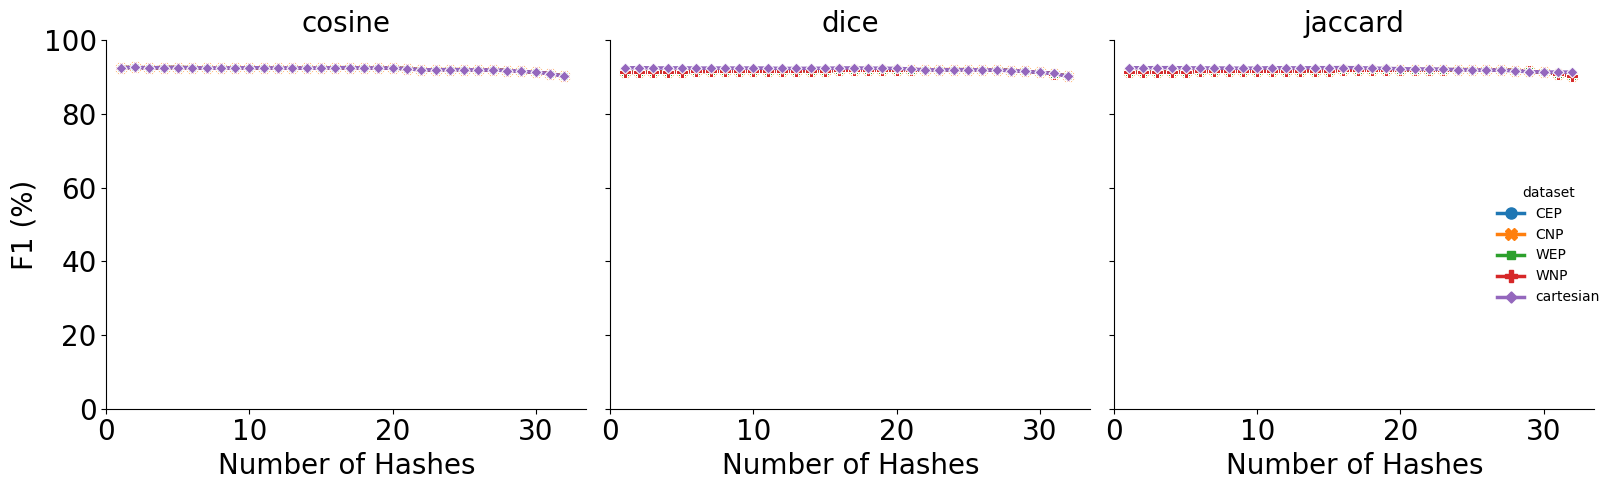

In [5]:
g = sns.relplot(
    data=max_f1,
    x="num_hashes",
    y="F1 %",
    hue="dataset",
    style="dataset",
    markers=True,
    dashes=False,      # solid lines but different markers
    col="similarity",
    kind="line",
    linewidth=2.5,
    markersize=8
)

for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=20)
    
g.set_axis_labels("Number of Hashes", "F1 (%)", fontsize=20)
g.set(xlim=(0, None), ylim=(0, 100))
g.set_titles("{col_name}", size=20)

plt.tight_layout()
plt.show()

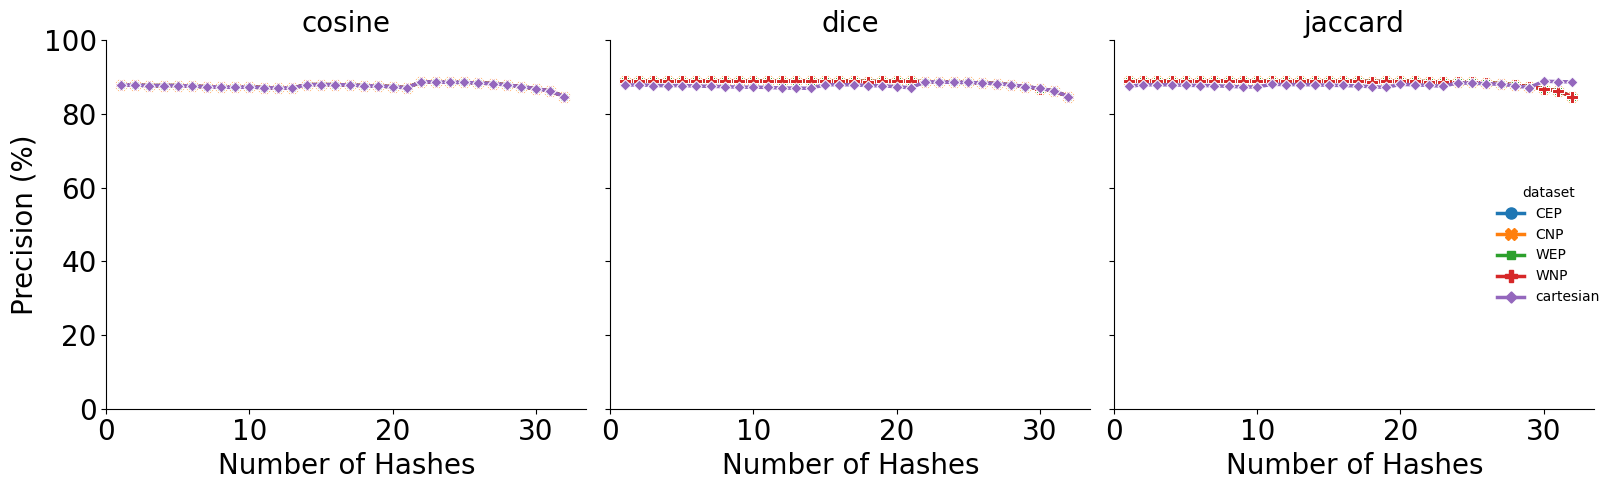

In [6]:
g = sns.relplot(
    data=max_f1,
    x="num_hashes",
    y="Precision %",
    hue="dataset",
    style="dataset",
    markers=True,
    dashes=False,      # solid lines but different markers
    col="similarity",
    kind="line",
    linewidth=2.5,
    markersize=8
)

for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=20)
    
g.set_axis_labels("Number of Hashes", "Precision (%)", fontsize=20)
g.set(xlim=(0, None), ylim=(0, 100))
g.set_titles("{col_name}", size=20)

plt.tight_layout()
plt.show()

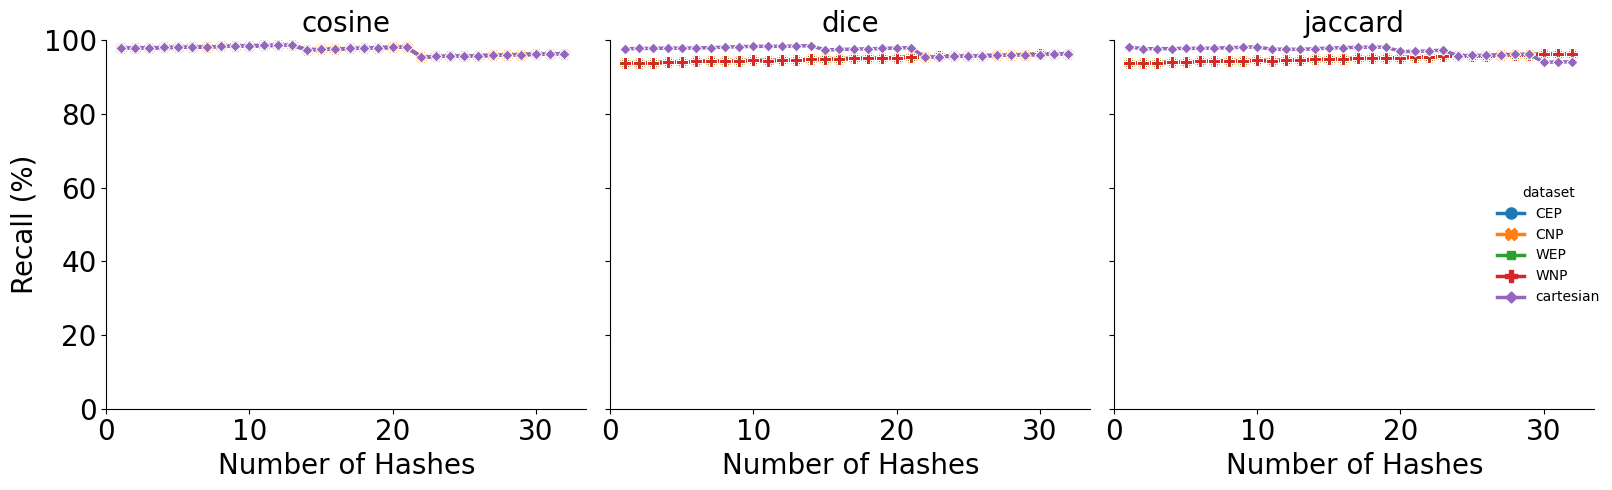

In [7]:
g = sns.relplot(
    data=max_f1,
    x="num_hashes",
    y="Recall %",
    hue="dataset",
    style="dataset",
    markers=True,
    dashes=False,      # solid lines but different markers
    col="similarity",
    kind="line",
    linewidth=2.5,
    markersize=8
)

for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=20)
    
g.set_axis_labels("Number of Hashes", "Recall (%)", fontsize=20)
g.set(xlim=(0, None), ylim=(0, 100))
g.set_titles("{col_name}", size=20)

plt.tight_layout()
plt.show()

In [8]:
result['attributes'].value_counts()

attributes
[title]    9120
Name: count, dtype: int64

In [9]:
result['offset'].value_counts()

offset
0    9120
Name: count, dtype: int64

In [10]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    9120
Name: count, dtype: int64

In [11]:
result['qgrams'].value_counts()

qgrams
4    9120
Name: count, dtype: int64

In [12]:
result['size'].value_counts()

size
1024    9120
Name: count, dtype: int64

In [13]:
result['num_hashes'].value_counts()

num_hashes
1     285
2     285
3     285
4     285
5     285
6     285
7     285
8     285
9     285
10    285
11    285
12    285
13    285
14    285
15    285
16    285
17    285
18    285
19    285
20    285
21    285
22    285
23    285
24    285
25    285
26    285
27    285
28    285
29    285
30    285
31    285
32    285
Name: count, dtype: int64